<a href="https://colab.research.google.com/github/caiohenry-jpg/CalculoNumerico/blob/main/AtividadePolinomioLagrange.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Interpolação polinomial
**Nome: Caio Henry**  
**RA: 180374**

### 1. Ideia central
Um exemplo seria estimar a temperatura entre dois horários de medição.
A estimativa pode ser prejudicada por erros do sensor ou mudanças
bruscas de temperatura. Interpolar é estimar dentro do intervalo
dos dados; extrapolar é estimar fora dele.

### 2. Dados, nós e grau
Os nós são os valores de x conhecidos. Com m nós distintos,
o polinômio interpolador tem grau no máximo m − 1.
Ao acrescentar um novo nó, a curva continua passando pelos pontos
antigos, mas seu formato pode mudar. Se o novo ponto já estiver
na curva, o polinômio permanece igual.

### 3. Tendência dos pontos
Os valores diminuem de 9 para 0, com diferenças de −5, −3 e −1.
O padrão sugere uma parábola. A curva não precisa ser uma reta.
Outras curvas podem passar pelos pontos, mas existe apenas um
polinômio de grau no máximo 3 que passa pelos quatro.


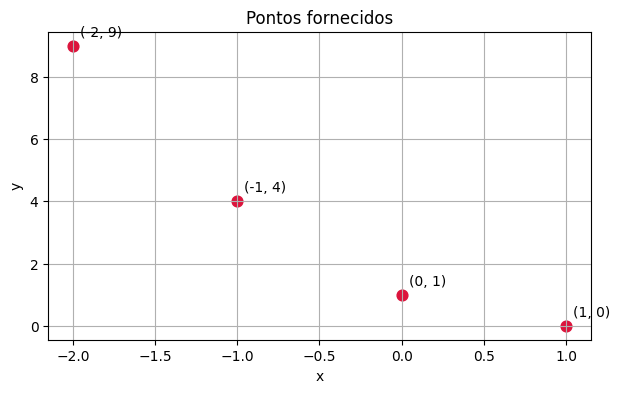

### 4. Polinômio interpolador

Polinômio: 1.0 - 2.0·x + 1.0·x² + (7.43830132e-16)·x³
Coeficientes: [ 1.00000000e+00 -2.00000000e+00  1.00000000e+00  7.43830132e-16]

x = -2.0 | y = 9.000000 | P(x) = 9.000000 | diferença = 5.33e-15
x = -1.0 | y = 4.000000 | P(x) = 4.000000 | diferença = 1.78e-15
x =  0.0 | y = 1.000000 | P(x) = 1.000000 | diferença = 6.66e-16
x =  1.0 | y = 0.000000 | P(x) = 0.000000 | diferença = 2.44e-15



O resultado é **P(x) = x² − 2x + 1**, de grau 2.
O coeficiente de x³ é praticamente zero, devido ao arredondamento.

As diferenças nos nós são muito pequenas. A conferência mostra
que o polinômio reproduz os dados, mas não garante que as estimativas
entre os nós ou fora do intervalo representem a realidade.


### 5. Visualização

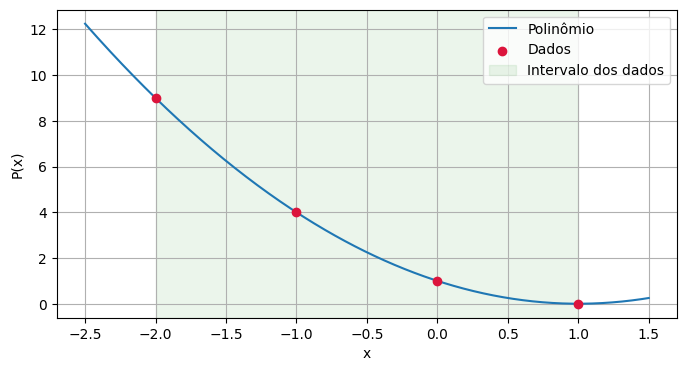


A curva passa pelos quatro pontos. Dentro de [−2, 1], temos
interpolação. Fora desse intervalo, temos extrapolação,
que não é confirmada pelos dados disponíveis.


### 6. Valores consultados

| x | P(x) | Classificação |
|---|---|---|
| -1.5 | 6.250000 | Interpolação |
| -0.5 | 2.250000 | Interpolação |
| 0.5 | 0.250000 | Interpolação |
| 0.9 | 0.010000 | Interpolação |
| 2 | 1.000000 | Extrapolação |


### Comparação de ferramentas

SymPy: t**2 - 2*t + 1

x = -1.5 | SymPy = 6.250000 | SciPy = 6.250000 | NumPy = 6.250000
x = 0.5 | SymPy = 0.250000 | SciPy = 0.250000 | NumPy = 0.250000



| Ferramenta | Entrada | Resultado | Facilidade ou dificuldade |
|---|---|---|---|
| [SymPy](https://docs.sympy.org/latest/modules/polys/reference.html#sympy.polys.polyfuncs.interpolate) | `sp.interpolate([(-2,9),(-1,4),(0,1),(1,0)], t)` | t² − 2t + 1; valores 6,25 e 0,25 | Fornece a expressão exata, mas exige conhecer os comandos. |
| [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html) | `BarycentricInterpolator(x, y)` | Valores 6,25 e 0,25 | Facilita calcular valores, mas não mostra diretamente a expressão expandida. |

As duas ferramentas concordaram com o NumPy.
O SciPy representa o mesmo polinômio x² − 2x + 1 na forma baricêntrica.


### 7. Dados de medição

Polinômio: 1.2 + 1.11666667·x - 0.45·x² + 0.13333333·x³
P_B(1.5) = 2.312500


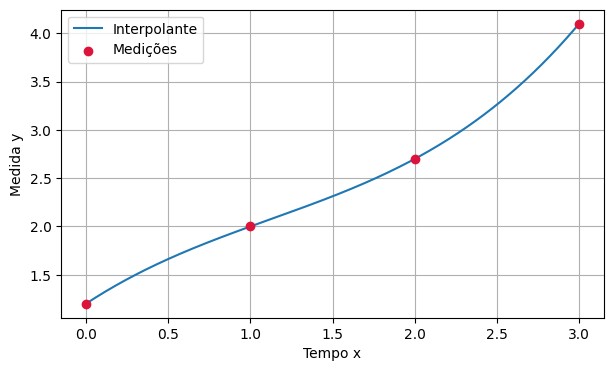


**P_B(x) = 1,2 + (67/60)x − (9/20)x² + (2/15)x³.**

Como 1,5 está entre os nós 1 e 2, trata-se de interpolação.
A estimativa é **2,3125**.


### 8. Alteração de uma medição

Valor original em 1.5: 2.312500
Valor alterado em 1.5: 2.593750
Diferença: 0.281250


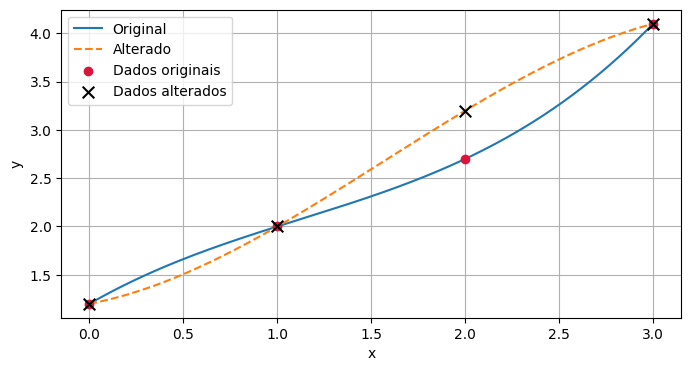


O ponto (2; 2,7) passou para (2; 3,2). A estimativa em 1,5
aumentou de **2,3125** para **2,59375**, uma diferença de **0,28125**.

A mudança não ficou restrita à região próxima ao ponto alterado.
O polinômio depende de todos os dados, então uma alteração pode
afetar a curva inteira, mantendo os outros nós. Por isso,
incertezas nas medições também afetam as estimativas.


### 9. Muitos nós e fenômeno de Runge

5 nós | erro máximo na malha: 0.438350 | erro nos nós: 1.17e-15
9 nós | erro máximo na malha: 1.045171 | erro nos nós: 4.52e-14
15 nós | erro máximo na malha: 7.192324 | erro nos nós: 1.87e-12


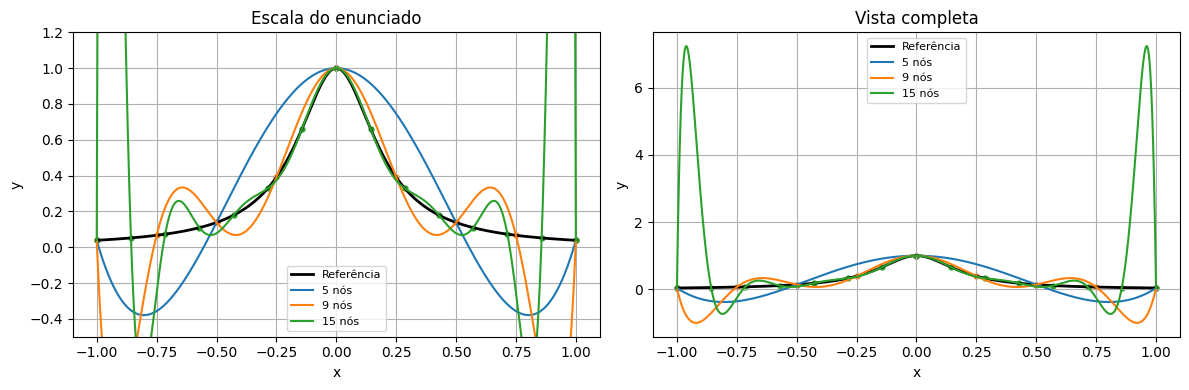


As curvas passam pelos seus respectivos nós, com pequenas
diferenças de arredondamento. Neste exemplo, aumentar o número
de nós igualmente espaçados provoca oscilações maiores perto
das extremidades, principalmente com 15 nós.

Esse é o fenômeno de Runge. Mais pontos não garantem uma
aproximação melhor. A escala limitada do primeiro gráfico
esconde parte das oscilações.

Para muitos dados, usaria interpolação por partes ou splines.
Se fosse possível escolher os nós, também avaliaria nós de
Chebyshev. O resultado depende dos dados, dos nós e do método.

### 10. Interpolação versus regressão

Passar por todas as medições não significa que elas estejam
corretas. A interpolação reproduz também os possíveis erros
presentes nos dados.

A regressão busca representar a tendência geral, sem precisar
passar por todos os pontos, e pode ser mais adequada quando
há ruído nas medições.

### 11. Síntese

Interpolar é estimar dentro do intervalo dos dados; extrapolar é estimar fora dele.  
Os nós são os valores de x conhecidos, nos quais o polinômio reproduz os dados.  
SymPy e SciPy foram comparados com o NumPy e apresentaram resultados iguais nas consultas.  
No primeiro conjunto, o polinômio encontrado foi P(x) = x² − 2x + 1.  
Ao aumentar y(2) em 0,5, a estimativa em 1,5 passou de 2,3125 para 2,59375.  
Essa alteração afetou a curva além da região próxima ao ponto modificado.  
No exemplo de Runge, o aumento de nós igualmente espaçados ampliou as oscilações.  
Usaria a interpolação para estimar temperaturas entre horários de medição.  
Teria cuidado com ruídos, grau elevado e estimativas fora do intervalo dos dados.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.interpolate import BarycentricInterpolator
from IPython.display import display, Markdown

def resposta(texto):
    display(Markdown(texto))


resposta("""
# Interpolação polinomial
**Nome: Caio Henry**
**RA: 180374**

### 1. Ideia central
Um exemplo seria estimar a temperatura entre dois horários de medição.
A estimativa pode ser prejudicada por erros do sensor ou mudanças
bruscas de temperatura. Interpolar é estimar dentro do intervalo
dos dados; extrapolar é estimar fora dele.

### 2. Dados, nós e grau
Os nós são os valores de x conhecidos. Com m nós distintos,
o polinômio interpolador tem grau no máximo m − 1.
Ao acrescentar um novo nó, a curva continua passando pelos pontos
antigos, mas seu formato pode mudar. Se o novo ponto já estiver
na curva, o polinômio permanece igual.

### 3. Tendência dos pontos
Os valores diminuem de 9 para 0, com diferenças de −5, −3 e −1.
O padrão sugere uma parábola. A curva não precisa ser uma reta.
Outras curvas podem passar pelos pontos, mas existe apenas um
polinômio de grau no máximo 3 que passa pelos quatro.
""")

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=60)
for xi, yi in zip(x, y):
    plt.annotate(
        f"({xi:g}, {yi:g})", (xi, yi),
        xytext=(5, 7), textcoords="offset points"
    )
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pontos fornecidos")
plt.grid(True)
plt.show()


resposta("### 4. Polinômio interpolador")

p = np.polynomial.Polynomial.fit(x, y, 3).convert()

print("Polinômio:", p)
print("Coeficientes:", p.coef)
print()

for xi, yi, pi in zip(x, y, p(x)):
    print(
        f"x = {xi:4.1f} | y = {yi:.6f} | "
        f"P(x) = {pi:.6f} | diferença = {abs(yi-pi):.2e}"
    )

resposta("""
O resultado é **P(x) = x² − 2x + 1**, de grau 2.
O coeficiente de x³ é praticamente zero, devido ao arredondamento.

As diferenças nos nós são muito pequenas. A conferência mostra
que o polinômio reproduz os dados, mas não garante que as estimativas
entre os nós ou fora do intervalo representem a realidade.
""")


resposta("### 5. Visualização")

xx = np.linspace(-2.5, 1.5, 400)

plt.figure(figsize=(8, 4))
plt.plot(xx, p(xx), label="Polinômio")
plt.scatter(x, y, color="crimson", zorder=3, label="Dados")
plt.axvspan(-2, 1, color="green", alpha=0.08,
            label="Intervalo dos dados")
plt.xlabel("x")
plt.ylabel("P(x)")
plt.grid(True)
plt.legend()
plt.show()

resposta("""
A curva passa pelos quatro pontos. Dentro de [−2, 1], temos
interpolação. Fora desse intervalo, temos extrapolação,
que não é confirmada pelos dados disponíveis.
""")


resposta("### 6. Valores consultados")

tabela = "| x | P(x) | Classificação |\n|---|---|---|\n"

for q in [-1.5, -0.5, 0.5, 0.9, 2.0]:
    tipo = "Interpolação" if x.min() <= q <= x.max() else "Extrapolação"
    tabela += f"| {q:g} | {p(q):.6f} | {tipo} |\n"

resposta(tabela)


resposta("### Comparação de ferramentas")

t = sp.symbols("t")
p_sympy = sp.interpolate([(-2, 9), (-1, 4), (0, 1), (1, 0)], t)
p_scipy = BarycentricInterpolator(x, y)

print("SymPy:", p_sympy)
print()

for q in [sp.Rational(-3, 2), sp.Rational(1, 2)]:
    print(
        f"x = {float(q):.1f} | "
        f"SymPy = {float(p_sympy.subs(t, q)):.6f} | "
        f"SciPy = {float(p_scipy(float(q))):.6f} | "
        f"NumPy = {p(float(q)):.6f}"
    )

resposta("""
| Ferramenta | Entrada | Resultado | Facilidade ou dificuldade |
|---|---|---|---|
| [SymPy](https://docs.sympy.org/latest/modules/polys/reference.html#sympy.polys.polyfuncs.interpolate) | `sp.interpolate([(-2,9),(-1,4),(0,1),(1,0)], t)` | t² − 2t + 1; valores 6,25 e 0,25 | Fornece a expressão exata, mas exige conhecer os comandos. |
| [SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.BarycentricInterpolator.html) | `BarycentricInterpolator(x, y)` | Valores 6,25 e 0,25 | Facilita calcular valores, mas não mostra diretamente a expressão expandida. |

As duas ferramentas concordaram com o NumPy.
O SciPy representa o mesmo polinômio x² − 2x + 1 na forma baricêntrica.
""")


resposta("### 7. Dados de medição")

xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, 3).convert()

print("Polinômio:", pB)
print(f"P_B(1.5) = {pB(1.5):.6f}")

xb = np.linspace(0, 3, 300)

plt.figure(figsize=(7, 4))
plt.plot(xb, pB(xb), label="Interpolante")
plt.scatter(xB, yB, color="crimson", zorder=3, label="Medições")
plt.xlabel("Tempo x")
plt.ylabel("Medida y")
plt.grid(True)
plt.legend()
plt.show()

resposta("""
**P_B(x) = 1,2 + (67/60)x − (9/20)x² + (2/15)x³.**

Como 1,5 está entre os nós 1 e 2, trata-se de interpolação.
A estimativa é **2,3125**.
""")


resposta("### 8. Alteração de uma medição")

yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(
    xB, yB_alterado, 3
).convert()

print(f"Valor original em 1.5: {pB(1.5):.6f}")
print(f"Valor alterado em 1.5: {pB_alterado(1.5):.6f}")
print(f"Diferença: {pB_alterado(1.5) - pB(1.5):.6f}")

plt.figure(figsize=(8, 4))
plt.plot(xb, pB(xb), label="Original")
plt.plot(xb, pB_alterado(xb), "--", label="Alterado")
plt.scatter(xB, yB, color="crimson", zorder=3, label="Dados originais")
plt.scatter(
    xB, yB_alterado, marker="x", color="black",
    s=70, zorder=4, label="Dados alterados"
)
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()
plt.show()

resposta("""
O ponto (2; 2,7) passou para (2; 3,2). A estimativa em 1,5
aumentou de **2,3125** para **2,59375**, uma diferença de **0,28125**.

A mudança não ficou restrita à região próxima ao ponto alterado.
O polinômio depende de todos os dados, então uma alteração pode
afetar a curva inteira, mantendo os outros nós. Por isso,
incertezas nas medições também afetam as estimativas.
""")


resposta("### 9. Muitos nós e fenômeno de Runge")

def f(t):
    return 1 / (1 + 25 * t**2)

tt = np.linspace(-1, 1, 1000)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

for eixo in eixos:
    eixo.plot(tt, f(tt), color="black", linewidth=2, label="Referência")

for n in [5, 9, 15]:
    tn = np.linspace(-1, 1, n)
    pn = np.polynomial.Polynomial.fit(tn, f(tn), n - 1).convert()

    erro = np.max(np.abs(pn(tt) - f(tt)))
    erro_nos = np.max(np.abs(pn(tn) - f(tn)))

    print(
        f"{n} nós | erro máximo na malha: {erro:.6f} | "
        f"erro nos nós: {erro_nos:.2e}"
    )

    for eixo in eixos:
        eixo.plot(tt, pn(tt), label=f"{n} nós")
        eixo.scatter(tn, f(tn), s=12)

eixos[0].set_ylim(-0.5, 1.2)
eixos[0].set_title("Escala do enunciado")
eixos[1].set_title("Vista completa")

for eixo in eixos:
    eixo.set_xlabel("x")
    eixo.set_ylabel("y")
    eixo.grid(True)
    eixo.legend(fontsize=8)

plt.tight_layout()
plt.show()

resposta("""
As curvas passam pelos seus respectivos nós, com pequenas
diferenças de arredondamento. Neste exemplo, aumentar o número
de nós igualmente espaçados provoca oscilações maiores perto
das extremidades, principalmente com 15 nós.

Esse é o fenômeno de Runge. Mais pontos não garantem uma
aproximação melhor. A escala limitada do primeiro gráfico
esconde parte das oscilações.

Para muitos dados, usaria interpolação por partes ou splines.
Se fosse possível escolher os nós, também avaliaria nós de
Chebyshev. O resultado depende dos dados, dos nós e do método.

### 10. Interpolação versus regressão

Passar por todas as medições não significa que elas estejam
corretas. A interpolação reproduz também os possíveis erros
presentes nos dados.

A regressão busca representar a tendência geral, sem precisar
passar por todos os pontos, e pode ser mais adequada quando
há ruído nas medições.

### 11. Síntese

Interpolar é estimar dentro do intervalo dos dados; extrapolar é estimar fora dele.
Os nós são os valores de x conhecidos, nos quais o polinômio reproduz os dados.
SymPy e SciPy foram comparados com o NumPy e apresentaram resultados iguais nas consultas.
No primeiro conjunto, o polinômio encontrado foi P(x) = x² − 2x + 1.
Ao aumentar y(2) em 0,5, a estimativa em 1,5 passou de 2,3125 para 2,59375.
Essa alteração afetou a curva além da região próxima ao ponto modificado.
No exemplo de Runge, o aumento de nós igualmente espaçados ampliou as oscilações.
Usaria a interpolação para estimar temperaturas entre horários de medição.
Teria cuidado com ruídos, grau elevado e estimativas fora do intervalo dos dados.
""")